## 3. 수치 해석에서의 오차 추정 
Estimation of Errors in Numerical Solutions

In [2]:
import numpy as np
%matplotlib inline
from matplotlib import pyplot as plt
# from scipy.optimize import root_scalar # Bisection Method

### 3.1. 구간법(Bracketing methods)

In [3]:
class BracketingNumericalAnalysis:
    """구간법 클래스"""

    def __init__(self, a: np.array, b: np.array, tolerance: float, max_iterations = 100):
        """
        Args:
            - a, b: 해가 존재하는 구간 양 끝 데이터 (1개의 해를 포함하는 구간을 설정해야 하므로 구간 설정 중요함)
            - c: 수치적 해법 반복 중 계산되는 근사값 초기화
            - tolerance: tolerance 값보다 작으면 학습 조기 종료시키는 기준
            - max_iterations: 최대 반복 횟수 (발산 시 무한루프 방지)
            - reference: 반복횟수, c, f(c) 기록용 리스트
        """
        self.a = a
        self.b = b
        self.c = 0
        self.tolerance = tolerance
        self.max_iterations = max_iterations
        self.reference = []

    def _checkBracket(self, f):
        """전제 조건 충족 확인 메서드
        
        Logics:
            - 사잇값 정리: 함수 f(x)가 닫힌 구간 [a,b]에서 연속이고 구간 양 끝에서 함수값의 부호가 달라야 실근 c가 적어도 하나 이상 존재
        
        Args:
            - f: 근을 찾으려는 대상 함수 선언, __init__()에 저장하지 않고 메서드 호출 시 인자 남겨받는 구조
        """
        if f(self.a) * f(self.b) >= 0:
            # 구간 (a,b) 양 끝 점의 함수값의 부호가 같을 경우(곱이 양수)
            raise ValueError(
                f"f({self.a:.4f}) and f({self.b:.4f}) must have opposite signs to apply the Intermediate Value Theorem for finding a root.")
                # 해당 구간에서 해가 존재하지 않음
        # else: 
        # f(self.a) * f(self.b) < 0: 
            # return
            # np.True_
    
    def _relativeError(self, c_new, c_old):
        """상대오차 계산 메서드
        
        Logics:
            - ε_a = |x_{new} - x_{old}| / |x_{new}| × 100%
            - 예외: x_{new}가 0에 가까울 경우
                   분모도 0에 가까워지므로 해당 경우 절대오차로 대체
        """
        if abs(c_new) < 1e-12:
            # 0.000000000001
            return abs(c_new - c_old)
        return (abs(c_new - c_old) / abs(c_new)) * 100


    def bisectionMethods(self, f):
        """이분법 적용 메서드
        
        Logics:
            - 구간의 중점을 다음 근사값으로 사용
        """
        self._checkBracket(f)
        a, b = self.a, self.b
        self.reference = []

        for i in range(self.max_iterations):
            self.c = (a + b) / 2.0
            fc = f(self.c)
            # 구간의 중점을 구함
            self.reference.append((
                (i + 1), # 반복 횟수
                self.c, # 수치해 근사값
                fc, # 근사값의 함수값
                (b - a) / 2.0 # 구간의 폭
            ))
            
            # 종료 조건
            if abs(fc) < self.tolerance or (b-a) / 2.0 < self.tolerance:
                # 함수값이 충분히 0에 가깝거나, 구간을 충분히 좁힌 경우
                return self.c, self.reference
                # 조건에 따라 반복을 조기 종료하고 수치해와 함수값 등 레퍼런스 히스트리 리스트 출력
            
            # 부호가 바뀐 쪽 구간을 선택해 다음 구간을 좁힘
            if f(a) * fc < 0:
                b = self.c
                # 해를 (a,c) 사이로 범위를 좁힘
                # 폐구간 끝점 b를 근사값 c로 대체
            elif fc * f(b) < 0:
                a = self.c
                # 해를 (c,b) 사이로 범위를 좁힘
                # 폐구간 첫점 a를 근사값 c로 대체
            else:
                pass

        return self.c, self.reference
        # 반복을 끝나고 수치해와 함수값 등 레퍼런스 히스트리 리스트 출력  
        # Q. Compute relative error(상대오차 epsilon)
    
    def regulaFalsiMethods(self, f):
        """가위치법 적용 메서드
        
        Logics:
            - 중점 대신 (a, f(a)), (b, f(b))를 잇는 직선이 x축과 만나는 점을 사용
            - [X][AS-IS] 함수 안에서 함수 호출하는 재귀 알고리즘(recursive algorithm) 적용
        """
        self._checkBracket(f)
        a, b = self.a, self.b
        self.reference = []    

        # 구간 경계에서 해가 존재한 경우
        for i in range(self.max_iterations):
            self.c = (a * f(b) - b * f(a)) / (f(b) - f(a))
            # 구간 양 끝 점을 잇는 직선
            fc = f(self.c)
            # 그 직선과 함수의 교점, x절편 c
            self.reference.append((
                (i + 1), # 반복 횟수
                self.c, # 수치해 근사값
                fc # 근사값의 함수값
            ))
    
            if abs(fc) < self.tolerance:
            # 함수값이 충분히 0에 가까울 경우
                return self.c, self.reference
                # 조건에 따라 반복을 조기 종료하고 수치해와 함수값 등 레퍼런스 히스트리 리스트 출력

            # 부호가 바뀐 쪽 구간을 선택해 다음 구간을 좁힘
            if f(a) * fc < 0:
                b = self.c
                # 해를 (a,c) 사이로 범위를 좁힘
                # 폐구간 끝점 b를 근사값 c로 대체
            elif fc * f(b) < 0:
                a = self.c
                # 해를 (c,b) 사이로 범위를 좁힘
                # 폐구간 첫점 a를 근사값 c로 대체
            else:
                pass

        return self.c, self.reference
        # 반복을 끝나고 수치해와 함수값 등 레퍼런스 히스트리 리스트 출력

#### 3.1.1. 이분법(Bisection method)

- 해가 구간 $(a,b)$ 사이에 있을 경우 $f(c) = 0$ 해가 존재하면 $f(a) \cdot f(b) < 0$ 조건 활용하여,
- 구간 중점 $c = \frac{a+b}{2}$ 중간값을 반복적으로 구하며, 매 단계마다 오차가 $\frac{1}{2}$씩 감소
  - $f(a) \cdot f(c) < 0$이면, 해를 $(a,c)$ 사이로 범위를 좁힘
  - $f(c) \cdot f(b) < 0$이면, 해를 $(c,b)$ 사이로 범위를 좁힘

In [7]:
solver = BracketingNumericalAnalysis(
    a = 0.0, b = 2.0, tolerance = 1e-5
)
# x³ - x - 2 = 0의 실근 x ≈ 1.5214 
# 구간 [0,2]로 설정

In [8]:
root, history =  solver.bisectionMethods(lambda x: x**3 - x - 2)
# root, history = solver.bisectionMethods(lambda x: e**x - x)
# ValueError: f(0.0000) and f(1.0000) must have opposite signs to apply the Intermediate Value Theorem for finding a root.

In [9]:
print(root)
print(history[0], history[-1],)

1.5213851928710938
(1, 1.0, -2.0, 1.0) (18, 1.5213851928710938, 3.260815724592803e-05, 7.62939453125e-06)


#### 3.1.2. 가위치법(Regula falsi method)

- 이분법보다 계산 효율을 높이기 위해 가위치(false position)를 사용
- 이 위치는 중점 대신 양 끝점을 직선으로 이었을 때 교점 사용, $\frac{f(a)}{c-a} = \frac{f(b)}{c-b}$
- a,b 두 점을 잇는 직선의 x절편 $c = \frac{af(b)-bf(a)}{f(b)-f(a)}$을 구하여 구간을 좁힘
- 즉, x절편을 새로운 근사값으로 선택하는 선형 보간법을 통해 오차를 약 $\frac{2}{3}$ 감소시킬 수 있음

In [10]:
root_, history_ = solver.regulaFalsiMethods(lambda x: x**3 - x - 2)
# root_, history_ = solver.regulaFalsiMethods(lambda x: e**x - x)

In [11]:
print(root_)
print(history_[0], history_[-1],)

1.5213791855449594
(1, 0.6666666666666666, -2.3703703703703702) (13, 1.5213791855449594, -3.0982556955549967e-06)


### 3.2. 개방법(Open methods)

[테일러 급수 전개]

- 테일러 급수란 어떤 점 $x_{i}$ 근처에서 함수 $f(x)$를 다항식으로 근사하는 방법
- 즉, $x_{i}$에서의 접선으로 $f(x)$를 근사하며, $f(x) = 0$이 되는 $x$를 찾는 것
- $f(x) ≈ f(x_i) + f'(x_i) * (x - x_i) \\
  0 = f(x_i) + f'(x_i) * (x - x_i) \\ 
  → x - x_i = -f(x_i) / f'(x_i) \\ 
  → x = x_i - f(x_i) / f'(x_i)$
- 접선이라는 1차식으로 잠깐 근사해서 그 1차식의 근을 구하고, 그걸 다음 추측값으로 쓰는 것을 반복하는 방법

In [12]:
class OpeningNumericalAnalysis:
    """개방법 클래스"""

    def __init__(self, x_0: np.array, tolerance: float, max_iterations = 100):
        """
        Args:
            - x: 초기값
            - c: 수치적 해법 반복 중 계산되는 근사값 초기화
            - tolerance: tolerance 값보다 작으면 학습 조기 종료시키는 기준
            - max_iterations: 최대 반복 횟수 (발산 시 무한루프 방지)
        """
        self.x_0 = x_0
        self.c = 0
        self.tolerance = tolerance
        self.max_iterations = max_iterations

    def _checkGradient(self, df_x0 = None):
        """전제 조건 충족 확인 메서드
        
        Logics:
            - 초기 접선/할선의 기울기(도함수값 또는 할선의 기울기 근사값)가 0에 가까울수록 발산하므로 사전 확인
            - 다음 근사값 계산식의 분모가 0에 가까워져서 x가 엄청 큰 값으로 튀어버리거나(overshoot), 아예 ZeroDivisionError가 날 수 있음
        Args:
            - df_x0: 현재 시점에서의 기울기
        """
        if df_x0 is not None and abs(df_x0) < 1e-12:
            raise ZeroDivisionError(
                "접선 또는 할선의 기울기가 0에 가까우므로 수렴 실패 가능성이 있습니다.")
    
    def _relativeError(self, c_new, c_old):
        """상대오차 계산 메서드
        
        Logics:
            - ε_a = |x_{new} - x_{old}| / |x_{new}| × 100%
            - 예외: x_{new}가 0에 가까울 경우
                   분모도 0에 가까워지므로 해당 경우 절대오차로 대체
        """
        if abs(c_new) < 1e-12:
            # 0.000000000001
            return abs(c_new - c_old)
        return (abs(c_new - c_old) / abs(c_new)) * 100

    def newtonMethods(self, f, df):
        """뉴턴-랩슨법 적용 메서드
        
        Logics:
            - 현재 근사값에서의 접선이 x축과 만나는 점을 다음 근사값으로 사용
            - 테일러 급수 전개: x_{i+1} = x_i - f(x_i) / f'(x_i)
        Args:
            - f: 근을 찾으려는 대상 함수
            - df: f의 도함수 f'(x), 수치 미분이 아니라, 해석적으로(미리 손으로) 구해서 넘겨줘야 함
        """
        self.c = self.x_0
        # 초기값에서 시작
        self.reference = []

        for i in range(self.max_iterations):
            fx = f(self.c)
            # 현재 근사값에서의 함수값
            dfx = df(self.c)
            # 현재 근사값에서의 기울기(접선의 기울기)

            self._checkGradient(dfx)
            # 접선의 기울기가 0에 가까울 경우(수평) 다음 x가 발산할 수 있으므로 예외 처리

            if abs(fx) < self.tolerance:
                # f(x)가 0에 충분히 가까워져 근을 찾았다고 판단될 경우
                return self.c, self.reference

            self.c = self.c - fx / dfx
            # 테일러 급수 전개에 따른 접선과 x축의 교점으로 근사값 갱신
            # relative_error = self._relativeError(self.c, x_old)
            # 상대오차 계산 과정 추가
            self.reference.append((i + 1, self.c, fx))

        return self.c, self.reference
 
    def secantMethods(self, f, x_2):
        """할선법 적용 메서드
        
        Logics:
            - 도함수 없이, 가장 최근 두 점을 지나는 할선(secant line)이 x축과 만나는 점을 다음 근사값으로 사용
            - (x_1, f(x_1), (x_2, f(x_2))
            - x_3 = x_2 - { f(x_2)*(x_2 - x_1) / (f(x_2) - f(x_1)) }
        Args:
            - f: 근을 찾으려는 대상 함수
            - x_2:
        """
        x_1 = self.x_0
        self.reference = [ (1, x_1, f(x_1)), (2, x_2, f(x_2)) ]
        # 반복 전 두 점 리스트에 미리 저장

        for i in range(2, self.max_iterations):
            f_1, f_2 = f(x_1), f(x_2)
            # 가장 최근 두 점의 함수값            
            self._checkGradient(f_2 - f_1)
            # 두 함수값의 사이가 0에 가까우면(할선의 기울기 거의 수평) 불안정하므로 예외 처리
            # 뉴턴법의 dfx 역할 → 할선법에서 f_2 - f_1

            self.c = x_2 - (f_2 * (x_2 - x_1) / (f_2 - f_1))
            f_c = f(self.c)
            # relative_error = self._relativeError(self.c, x_old)
            # 상대오차 계산 과정 추가
            self.reference.append(((i+1), self.c, f_c))

            if abs(f_c) < self.tolerance:
                return self.c, self.reference

            x_1, x_2 = x_2, self.c
            # 가장 최근 두 점으로 창을 옮김            

        return self.c, self.reference

#### 3.2.1. 뉴턴법(Newton-Raphson method)

- 함수가 미분 가능한 연속 함수일 경우에,선형 근사하고 $x_{i+1}$에서 $x$축과 교점이 생기는 경우
- $0 = f(x_{i+1}) = f(x_i) + f'(x_i)(x_i+1-x_i)$
- 접선의 x절편 $x_{i+1} = x_i -\frac{f(x_i)}{f'(x_i)}$
- 수렴 속도가 이차 수렴(quadratic convergence)으로 매우 빠름
- 다만, 수렴하지 않고 local extrema 근처에서 진동(발산)할 수 있으므로 초기 추정값이 해에서 멀지 않도록 하는게 중요함

In [14]:
f = lambda x: np.exp(-x) - x
# f(x) = e^{-x} - x

solver = OpeningNumericalAnalysis(
    x_0 = 1.0,
    tolerance = 1e-5
)
# 초기값 1, 수렴 조건 0.00001(10만 분의 1)로 설정

In [15]:
df = lambda x: -np.exp(-x) - 1
# 뉴턴법: 도함수 f'(x) = -e^{-x} - 1 를 직접 넘김

root_newton, history_newton = solver.newtonMethods(f, df)

In [16]:
print(root_newton)
print(history_newton[0], history_newton[-1],)

0.567143285989123
(1, 0.5378828427399902, -0.6321205588285577) (3, 0.567143285989123, 0.0002449498638371628)


#### 3.2.2. 할선법(Secant method)

- 뉴턴법에 따라 미분하기 어려워 도함수 $f'(x)$를 직접 구하기 어려울 때, 두 점을 잇는 할선의 기울기로 대체
- $f'(x) \approx \frac{f(x_i)-f(x_{i-1})}{x_i-x_{i-1}}$ 기울기 대신 수치적으로 근사 미분값 사용
- $x_{i+1} = x_i - \frac{f(x_i)(x_i-x_{i-1})}{f(x_i)-f(x_{i-1})}$

In [18]:
f = lambda x: np.exp(-x) - x
# f(x) = e^{-x} - x

solver = OpeningNumericalAnalysis(x_0 = 0, tolerance = 1e-5)
# 초기값 0, 수렴 조건 0.00001(10만 분의 1)로 설정

root_secant, history_secant = solver.secantMethods(f, x_2 = 1.0)
# 할선법: 두 번째 초기값 x_2만 추가로 넘기면 됨 (도함수 불필요)

In [19]:
print(root_secant)
print(history_secant[0], history_secant[-1],)

0.5671433066049633
(1, 0, 1.0) (6, 0.5671433066049633, -2.5380166635002865e-08)


## 4. 선형방정식의 반복 해법


In [ ]:
class IterativeNumericalAnalysis:
    """반복법 클래스"""

    def __init__(self, A: np.ndarray, b: np.ndarray, x_0: np.ndarray = None,
                 tolerance: float = 1e-6, max_iterations: int = 100):
        """
        Args:
            - A: 계수 행렬 (N x N)
            - b: 상수 벡터 (N)
            - n: 방정식이 몇 차원인지 걔산
            - x: 초기  해 벡터 (N)
            - c: 수치적 해법 반복 중 계산되는 근사값 초기화
            - tolerance: tolerance 값보다 작으면 학습 조기 종료시키는 기준
            - max_iterations: 최대 반복 횟수 (발산 시 무한루프 방지)
        """
        self.A = np.array(A, dtype = float)
        # 컴퓨터가 소수점 계산을 정확하게 할 수 있도록 모든 숫자를 실수(float) 데이터 타입 변환
        self.b = np.array(A, dtype = float)
        self.n = len(b)
        self.x_0 = np.zeros(self.n) if x_0 is None else np.array(x_0, dtype = float)

        self.tolerance = tolerance
        self.max_iterations = max_iterations
        self.reference = []

    def _checkDiagonal(self, df_x0 = None):
        """전제 조건 충족 확인 메서드
        
        Logics:
            - 대각 성분에 0이 존재하는지 확인
        """
        if np.any( np.abs( np.diag(self.A) ) < 1e-12 ):
            # 계수 행렬의 각 행에서 대각 성분의 절댓값이 나머지 원소들의 합보다 크지 않은지
            raise ValueError(
                "계수 행렬이 대각 우세 조건이 성립하지 않으므로, 대각 성분 중에 0에 가까운 값이 존재하여 연산할 수 없습니다.")
    
    def _relativeError(self, x_new: np,array, x_old: np.array):
        """근사 상대오차 계산 메서드
        
        Logics:
            - ε_a = |x_{new} - x_{old}| / |x_{new}| × 100%
            - 예외: x_{new}가 0에 가까울 경우 분모도 0에 가까워지므로 해당 경우 절대오차로 대체
            - [TO-BE] 기존 스칼라용 공식 벡터로 확장 후: 무한 노름을 이용하여 절대 오차의 최댓값 계산
            - [AS-IS] 오차의 상한선(upper bound)을 분석하는 조건수(condition number) 계산에도 무한 노름 활용
        """
        norm_new = np.linalg.norm(x_new, org = np.inf)
        # 벡터의 무한 노름 (벡터 원소들의 절대값 중 최댓값)
        # 행렬의 무한 노름 (행렬의 각 행의 절대값 합 중 최댓값)

        if norm_new < 1e-12:
        # if abs(c_new) < 1e-12:
            # 0.000000000001
            return np.linalg.norm(x_new - x_old, org = np.inf)
            # 절대 오차로 대체
            # return abs(c_new - c_old)

        return ( np.linalg.norm(x_new - x_old, org = np.inf) / norm_new ) * 100
        # return (abs(c_new - c_old) / abs(c_new)) * 100

    def jacobiIterationsMethods(self):
        """자코비 반복법 적용 메서드
        
        Logics:
            - 대각분할(A = D + L + U, A_1 = D) 기반 반복법
            - x_i^{k+1} = ( b_i - sum(j != i) A_{ij} x_j^{k} ) / A_{ii}
        Args:
            - 
        """

        return self.reference
 
    def gaussSeidelMethods(self):
        """가우스-자이델 반복법 적용 메서드
        
        Logics:
            - A_1 = D + L 분할을 이용하여, i번째 변수를 구하는 즉시 
              최근 x_i^{k+1} 값을 동일 반복 단계의 다음 변수 계산(j > 1)에 반영하는 반복법
        Args:
            - 
        """

        return self.reference

#### 4.0. 단순 고정점 반복법(Fixed‐point iteration method)

[요약]

- $f(x) = 0$을 $x = g(x)$ 형태로 바꾼 후, $x_{i+1} = g(x_i)$를 반복 대입하며, $|g'(x)| < 1|$ 조건에서 수렴 (also called “Lipschitz continuous”)
- 근사 상대 오차(Estimated relative error)를 통해 반복법의 수렴 여부를 판단하기 위한 이전 단계 및 현재 단계의 해를 비교함


[원리]
- 개요: $\begin{cases} y = x \\ y = g(x) \end{cases}$를 $x = g(x)$의 형태로 식을 표현하여 계산값을 연속 대입하여 수렴시킴 
    - $0 < g' <1$, 점진적 수렴
    - $-1 < g' < 0$, 진동 수렴
    - $g' > 1 \ or \ g' < -1$, 발산
- 절차:
  * 초기 추정치는 $x_{0}$
  * $x_{1} = g(x_{0})$로 $x_{1}$ 결정, 일반적으로 $x_{i+1} = g(x_i)$
  * 계산 중단조건은 상대오차인 $\epsilon_{a} = |\frac{x_{i+1} - x_{i}}{x_{i+1}}| < \epsilon_{s}$, Y이면 Exit이고 그렇지 않으면 반복
- 장점: $g(x)$ 결정의 융통성과 방법의 단순성
- 단점: $|g'(x) < 1|$일 때만 수렴


[예]
- $y = x^2 - 3x + e^x -2 = 0$
- 단순 고정점 반복법 사용하기 위해, $x = g(x) = \frac{x^2 - e^x - 2}{3}$로 식 변환
- 작은 해는 [-1,0] 범위에 있으므로 이 범위에서 수렴성 체크, $g'(x) = \frac{1}{3} (2x + e^x) \rightarrow |g'(x) < 1|$
- (cf.) 만약 $x = g(x) = -\sqrt{3x - e^x + 2}$

#### 4.1. 야코비 반복법(Jacobi Iterative Method)

[요약]
- $A_{1} = D$로 한 경우
- Jacobi method를 적용하면 n+1번째 step에서 i번째 항은 n번째 off-diagnal 항을 이용해서 계산할 수 있다. (변수의 동시적 갱신)

[원리]
- $\begin{cases} a_{11}x_{1} + a_{12}x_{2} + a_{13}x_{3} = b_{1} \\ a_{21}x_{1} + a_{22}x_{2} + a_{23}x_{3} = b_{2} \\ a_{31}x_{1} + a_{32}x_{2} + a_{33}x_{3} = b_{3}  \end{cases}$
$\begin{cases} x_{1} = \frac{1}{a_{11}} (b_{1} - a_{12}x_{2} - a_{13}x_{3}) \\  x_{2} = \frac{1}{a_{21}} (b_{2} - a_{22}x_{1} - a_{23}x_{3}) \\ x_{3} = \frac{1}{a_{31}} (b_{3} - a_{32}x_{1} - a_{33}x_{2}) \end{cases}$
- 단, 계수행렬 중 대각행렬값은 $a_{ii} \neq 0$, n개의 초기값이 필요하다.
- 수렴판별조건은 $\epsilon_{a,j} = \frac{x_{i} - x_{i-1}}{x_{i}} <= \epsilon_{s}$

#### 4.2. 가우스 자이델 반복법(Gauss-Seidel Iterative Method)

[요약]
- 선형대수방정식 [A]{x} = {b}을 푸는 반복법 중 가장 보편적인 방법이다. (변수의 순차적 갱신)
- $A = L + D + U$라고 생각했을 때, $A_{1} = L + D$인 방법이다.

[원리]
- $\begin{cases} a_{11}x_{1} + a_{12}x_{2} + a_{13}x_{3} = b_{1} \\ a_{21}x_{1} + a_{22}x_{2} + a_{23}x_{3} = b_{2} \\ a_{31}x_{1} + a_{32}x_{2} + a_{33}x_{3} = b_{3}  \end{cases}$
$\begin{cases} x_{1} = \frac{1}{a_{11}} (b_{1} - a_{12}x_{2} - a_{13}x_{3}) \\  x_{2} = \frac{1}{a_{21}} (b_{2} - a_{22}x_{2} - a_{23}x_{3}) \\ x_{3} = \frac{1}{a_{31}} (b_{3} - a_{32}x_{2} - a_{33}x_{3}) \end{cases}$
- 단, 계수행렬 중 대각행렬값은 $a_{ii} \neq 0$, n-1개의 초기값이 필요하다.
- 수렴판별조건은 $\epsilon_{a,j} = \frac{x_{i} - x_{i-1}}{x_{i}} <= \epsilon_{s}$

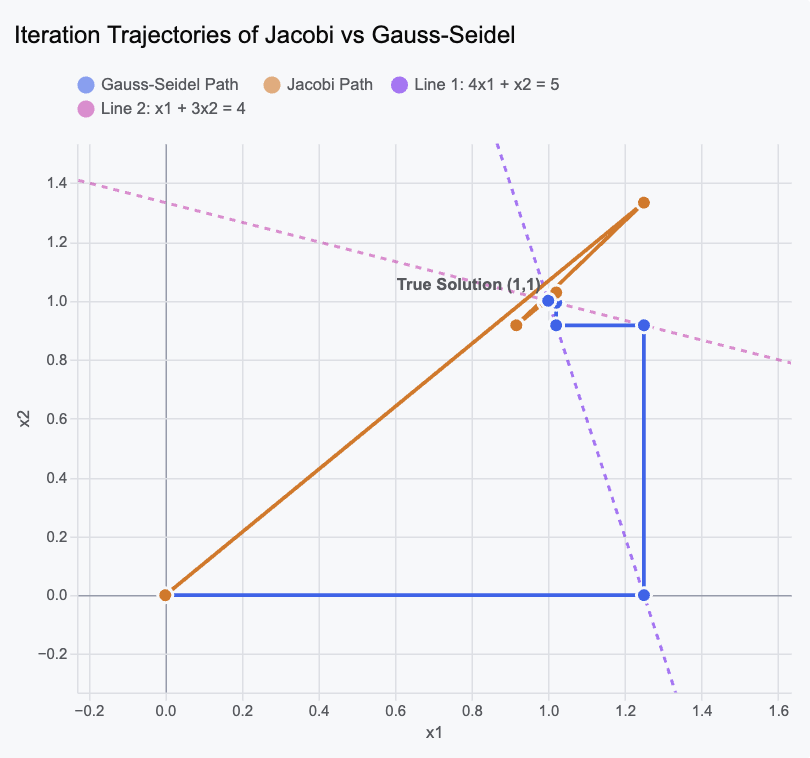

---

## 5. 커브 피팅

---

## 6. 보간법

6.1. Standard (일반 다항식 보간법) — 연립방정식으로 계수 구하기

6.2. Lagrange 보간법 — 라그랑주 기저다항식으로 보간하기

6.3. Newton 보간법 — 분할차분으로 계수 구하기